In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

1. SETUP VISUALISASI (Tema UNIB: Biru Tua, Kuning, Putih)

In [3]:
UNIB_BLUE = '#003366'
UNIB_YELLOW = '#FFD700'
UNIB_WHITE = '#FFFFFF'
plt.rcParams['figure.facecolor'] = UNIB_WHITE
plt.rcParams['axes.facecolor'] = UNIB_WHITE
plt.rcParams['axes.edgecolor'] = UNIB_BLUE
plt.rcParams['text.color'] = UNIB_BLUE
plt.rcParams['axes.labelcolor'] = UNIB_BLUE
plt.rcParams['xtick.color'] = UNIB_BLUE
plt.rcParams['ytick.color'] = UNIB_BLUE
plt.rcParams['font.family'] = 'sans-serif'

2. SIMULASI DATA CITRA SATELIT (SENTINEL 1 & 2)

In [4]:
print("Mengumpulkan data fusi Sentinel-1 (Radar) dan Sentinel-2 (Optik)...")

num_samples = 1000
image_size = 64
channels = 4 # 3 channel RGB (Optik) + 1 channel SAR (Radar)
num_classes = 5

# Membuat data latih sintetis (dummy data) untuk simulasi
X_train = np.random.rand(num_samples, image_size, image_size, channels)
y_train = np.random.randint(0, num_classes, num_samples)

# Membagi data latih dan validasi
X_val = X_train[:200]
y_val = y_train[:200]
X_train = X_train[200:]
y_train = y_train[200:]

class_names = ['Tani Kecil', 'Tani Besar', 'Tambang', 'Tebang Selektif', 'Kebakaran/Banjir']

Mengumpulkan data fusi Sentinel-1 (Radar) dan Sentinel-2 (Optik)...


3. MEMBANGUN ARSITEKTUR CNN

In [5]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(image_size, image_size, channels)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


4. TRAINING MODEL

In [6]:
print("\nMelatih model CNN untuk mengenali pola pendorong deforestasi...")
history = model.fit(X_train, y_train, epochs=10,
                    validation_data=(X_val, y_val), verbose=1)


Melatih model CNN untuk mengenali pola pendorong deforestasi...
Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 147ms/step - accuracy: 0.1863 - loss: 1.6265 - val_accuracy: 0.2050 - val_loss: 1.6089
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 131ms/step - accuracy: 0.2212 - loss: 1.6091 - val_accuracy: 0.2000 - val_loss: 1.6094
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 157ms/step - accuracy: 0.2188 - loss: 1.6088 - val_accuracy: 0.2000 - val_loss: 1.6095
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 132ms/step - accuracy: 0.2188 - loss: 1.6084 - val_accuracy: 0.2000 - val_loss: 1.6095
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 130ms/step - accuracy: 0.2188 - loss: 1.6081 - val_accuracy: 0.2000 - val_loss: 1.6097
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 135ms/step - accuracy: 0.2188 - loss: 1.6080 - val_accuracy: 0.2000 - val_loss: 1.6099
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 135ms/step - accuracy: 0.2188 - loss: 1.6079 - val_accuracy: 0.2000 - val_loss: 1.6100
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 4

5. VISUALISASI HASIL PELATIHAN (Tema UNIB)

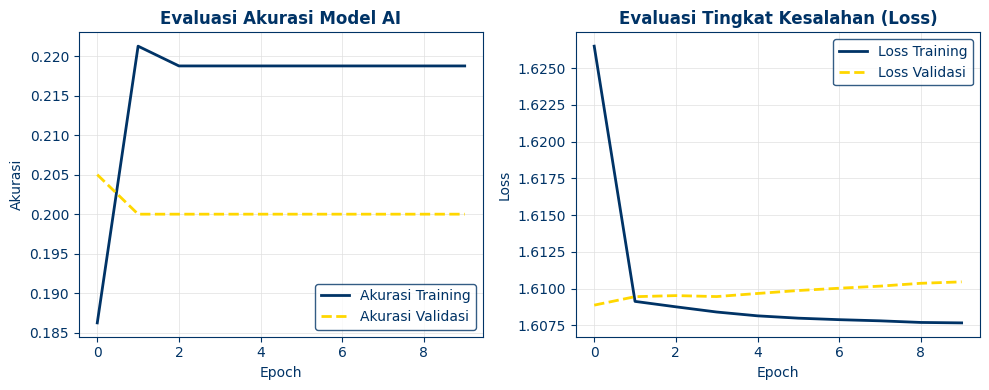


Kesimpulan: Model siap digunakan untuk mengklasifikasikan alert deforestasi mingguan.


In [7]:
plt.figure(figsize=(10, 4))

# Plot Akurasi
plt.subplot(1, 2, 1)
# Garis Training warna Biru Tua, Validasi warna Kuning
plt.plot(history.history['accuracy'], label='Akurasi Training', color=UNIB_BLUE, linewidth=2)
plt.plot(history.history['val_accuracy'], label='Akurasi Validasi', color=UNIB_YELLOW, linewidth=2, linestyle='--')
plt.title('Evaluasi Akurasi Model AI', color=UNIB_BLUE, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')
plt.legend(facecolor=UNIB_WHITE, edgecolor=UNIB_BLUE)
plt.grid(color='#E0E0E0', linestyle='-', linewidth=0.5) # Grid abu-abu sangat muda agar tidak mengganggu

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Loss Training', color=UNIB_BLUE, linewidth=2)
plt.plot(history.history['val_loss'], label='Loss Validasi', color=UNIB_YELLOW, linewidth=2, linestyle='--')
plt.title('Evaluasi Tingkat Kesalahan (Loss)', color=UNIB_BLUE, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(facecolor=UNIB_WHITE, edgecolor=UNIB_BLUE)
plt.grid(color='#E0E0E0', linestyle='-', linewidth=0.5)

plt.tight_layout()
plt.show()

print("\nKesimpulan: Model siap digunakan untuk mengklasifikasikan alert deforestasi mingguan.")